# M13.13 — Eventos reales: modelos G3 frente a modelos G3T

Comparación **descriptiva** de los mismos 9 eventos de M13.7, con exactamente el mismo procesado, entre modelos
entrenados en G3 y en G3T. Sólo cambia el modelo. El taper de G3T afecta a las formas de onda de entrenamiento, no al
procesado de los datos reales.

- **Gate:** con `M13_4b_G3aug_s123` se reproducen las predicciones de M13.7 (|Δ| ≤ 1e−4 físico). Si falla, el notebook se detiene antes de evaluar los demás modelos.
- **Medidas:** por evento y modelo, predicción, residuo (predicción − mediana de la posterior LVK `C01:Mixed`, sistema del detector) y cuantil de la predicción en la posterior.
- **Sin Mondrian:** requiere calibrar cada modelo nuevo en cal; queda para más adelante.

> **Roles.** Evaluación solamente: los eventos reales no intervienen en la elección de modelo ni en ningún ajuste.
> Con n = 9, cohorte seleccionada, no se hacen tests. LVK es una referencia, no la verdad conocida.

Inferencia en CPU. Ejecutar por secciones. Entregado sin ejecutar.

## 1. Parámetros

In [1]:
# Checkpoints relative to <data_root>/models/checkpoints/. Keys are checkpoint tags: each model's
# run_info.json is read from <data_root>/results/M13_3/<tag>/.
GATE_TAG = "M13_4b_G3aug_s123"
GATE_CHECKPOINT = "M13_3/M13_4b_G3aug_s123_final.pt"
MODELS = {
    "M13_4a_G3aug_s123": "M13_3/M13_4a_G3aug_s123_final.pt",
    "M13_13_4a_G3T_s123": "M13_3/M13_13_4a_G3T_s123_final.pt",
    "M13_13_4b_G3T_s123": "M13_3/M13_13_4b_G3T_s123_final.pt",  # uncomment together with its pair below
}
# (old, new) pairs for the per-event table and figure. The gate model is available as "old".
COMPARISONS = [
    ("M13_4a_G3aug_s123", "M13_13_4a_G3T_s123"),
    ("M13_4b_G3aug_s123", "M13_13_4b_G3T_s123"),
]
HIGHLIGHT = {"GW191230_180458": "masa alta", "GW200202_154313": "baja masa", "GW200316_215756": "baja masa"}

M13_7_RUN = "run_20261102T164134Z"  # the only M13.7 run with real-event outputs
GATE_TOLERANCE = 1e-4  # physical units, per label
DEVICE = "cpu"

## 2. Imports y rutas

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import sys, ast, json, hashlib, inspect, re, urllib.request
import h5py
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

root = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if root is None:
    raise RuntimeError("Abrir desde cbc_pe")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.paths import resolve_project_root, resolve_data_root, resolve_processed_artifact
from src.config import SimulationConfig
from src.processing import SignalProcessor
from src.models import network
from src.models.dataset import normalize_input_per_sample_per_detector_zscore
from src.real_data.catalog import get_event_detector_url
from src.real_data.gwosc_utils import read_gwosc_hdf5_as_pycbc_timeseries
from src.real_data.signal_processing import build_real_input_like_training, event_window_is_available_and_finite
from src.real_data.psd import select_valid_psd_window, estimate_offsource_psd
from src.real_data.inference import predict_real_with_embeddings
import scripts.generate_m11_final_G1 as g1
from scripts.m13.generate_m13_G2_band import apply_overrides, config_sha256
from scripts.m13.generate_m13_G3_whitening import load_m13_config

PROJECT_ROOT = resolve_project_root()
def read_json(path):
    return json.loads(Path(path).read_text())
def require(condition, message):
    if not condition:
        raise ValueError(message)
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

LABELS = ["chirp_mass", "total_mass", "chi_eff"]
DETECTORS = ["H1", "L1", "V1"]
ALL_MODELS = {GATE_TAG: GATE_CHECKPOINT, **MODELS}
require(len(ALL_MODELS) == len(MODELS) + 1, "The gate model must not be repeated in MODELS")
require(all(tag in ALL_MODELS for pair in COMPARISONS for tag in pair), "COMPARISONS uses a model not in MODELS")

# G3 processing contract, as in M13.7: its train config supplies the dataset and the input normalization.
TRAIN_CFG_PATH = PROJECT_ROOT / "configs/experiments/m13/train_m13_4b_G3aug_s123.json"
GEN_M13_PATH = PROJECT_ROOT / "configs/generation/generate_m13_G3_band1024_w16.json"
train_cfg = read_json(TRAIN_CFG_PATH)
DATA_ROOT = resolve_data_root(config_data_root=train_cfg["data_root"])
DATASET_ID = train_cfg["dataset"]["dataset_id"]
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
                                   file_name=train_cfg["dataset"]["dataset_file"])
CHECKPOINT_ROOT = DATA_ROOT / "models/checkpoints"

M13_7_NOTEBOOK = PROJECT_ROOT / "notebooks/m13/M13_7_pipeline_provisional_4b.ipynb"
M13_7_DIR = DATA_ROOT / "results/M13_3" / GATE_TAG / "M13_7_pipeline_provisional" / M13_7_RUN
M13_7_STAMP = M13_7_RUN.removeprefix("run_")
M13_7_SUMMARY = M13_7_DIR / f"M13_7_summary_{M13_7_STAMP}.json"
M13_7_PREDICTIONS = M13_7_DIR / "real_event_predictions.csv"
M13_7_STATUS = M13_7_DIR / "real_event_status.csv"
M13_7_PE = M13_7_DIR / "real_lvk_pe_comparison.csv"

# Real-event cohort and cache exactly as M13.7/M11.14.
M10_DATASET_ID = read_json(PROJECT_ROOT / "configs/experiments/train_500k_M10_inputzscore_resdilated_emb64_d124_bs256_seed123.json")["dataset"]["dataset_id"]
EVENT_LIST_PATH = DATA_ROOT / "results" / M10_DATASET_ID / "real_events_m10_500k_lvk_comparison/multi_event_all_catalog_candidates.csv"
GWOSC_CACHE = DATA_ROOT / "gwosc_cache"

# Same choice of posterior samples as M13.7, section 6b.
PE_DIR = DATA_ROOT / "external/gwtc3_pe"
PE_VARIANT = "mixed_cosmo"
PE_GROUP = "C01:Mixed"
PE_LEVEL = 0.90
PE_Q = [(1 - PE_LEVEL) / 2, 1 - (1 - PE_LEVEL) / 2]

# File names carry the run stamp: a later run with more models adds files and replaces none.
RUN_STAMP = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUTPUT_DIR = DATA_ROOT / "results/M13_3/M13_13/real_events"

inputs_to_check = [("M13.7 notebook", M13_7_NOTEBOOK), ("M13.7 summary", M13_7_SUMMARY),
    ("M13.7 predictions", M13_7_PREDICTIONS), ("M13.7 status", M13_7_STATUS), ("M13.7 PE comparison", M13_7_PE),
    ("G3 HDF5", G3_H5), ("G3 generation config", GEN_M13_PATH), ("cohort", EVENT_LIST_PATH)]
for tag, relative in ALL_MODELS.items():
    inputs_to_check += [(f"checkpoint {tag}", CHECKPOINT_ROOT / relative),
                        (f"run_info {tag}", DATA_ROOT / "results/M13_3" / tag / "run_info.json")]
path_audit = pd.DataFrame([dict(role=r, path=str(p), exists=p.is_file()) for r, p in inputs_to_check])
with pd.option_context("display.max_colwidth", None):
    display(path_audit)
require(path_audit.exists.all(), "Missing required inputs; inspect path table")

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


,role,path,exists
0,M13.7 notebook,/afs/ciemat.es/user/v/vserrano/Desktop/gw/Gravitational-Waves-Lab/cbc_pe/notebooks/m13/M13_7_pipeline_provisional_4b.ipynb,True
1,M13.7 summary,/data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z/M13_7_summary_20261102T164134Z.json,True
2,M13.7 predictions,/data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z/real_event_predictions.csv,True
3,M13.7 status,/data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z/real_event_status.csv,True
4,M13.7 PE comparison,/data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/M13_7_pipeline_provisional/run_20261102T164134Z/real_lvk_pe_comparison.csv,True
5,G3 HDF5,/data/vserrano/cbc_pe_data/processed/M13_G3_band1024_w16_500k/m13_G3_band1024_w16_500k_trainio.h5,True
6,G3 generation config,/afs/ciemat.es/user/v/vserrano/Desktop/gw/Gravitational-Waves-Lab/cbc_pe/configs/generation/generate_m13_G3_band1024_w16.json,True
7,cohort,/data/vserrano/cbc_pe_data/results/bbh_processed_4s_seobnrv4opt_snr10-25_n500_000/real_events_m10_500k_lvk_comparison/multi_event_all_catalog_candidates.csv,True
8,checkpoint M13_4b_G3aug_s123,/data/vserrano/cbc_pe_data/models/checkpoints/M13_3/M13_4b_G3aug_s123_final.pt,True
9,run_info M13_4b_G3aug_s123,/data/vserrano/cbc_pe_data/results/M13_3/M13_4b_G3aug_s123/run_info.json,True


## 3. Procesado: código de M13.7, sin copiarlo

M13.7 definió el procesado dentro de su notebook, que está cerrado. Para que el procesado sea exactamente el mismo,
aquí no se reescribe: `reuse_m13_7` ejecuta el código fuente de esas celdas y guarda su sha256 en el JSON.

| Celda de M13.7 | Qué se reutiliza |
|---|---|
| 16 | Contrato G3: `processor`, contexto, PSD y comprobaciones frente a los atributos del HDF5 |
| 19 | `prepare_nominal`, `check_psd_equivalence` |
| 27 | `pe_file`, `read_pe_samples` |

In [3]:
m13_7_cells = read_json(M13_7_NOTEBOOK)["cells"]
reused_sources = {}

def reuse_m13_7(cell_index, names=None):
    """Run a code cell of the closed M13.7 notebook here, or only the functions in `names`."""
    cell = m13_7_cells[cell_index]
    require(cell["cell_type"] == "code", f"M13.7 cell {cell_index} is not code")
    source = "".join(cell["source"])
    tree = ast.parse(source)
    if names is not None:
        tree.body = [n for n in tree.body if isinstance(n, ast.FunctionDef) and n.name in names]
        require({n.name for n in tree.body} == set(names), f"M13.7 cell {cell_index} does not define {names}")
    reused_sources[f"cell_{cell_index}"] = dict(names=names, sha256=hashlib.sha256(source.encode()).hexdigest())
    exec(compile(tree, f"M13_7_cell_{cell_index}", "exec"), globals())

reuse_m13_7(16)
reuse_m13_7(19, ["prepare_nominal", "check_psd_equivalence"])
reuse_m13_7(27, ["pe_file", "read_pe_samples"])
print(json.dumps(reused_sources, indent=2))

{
  "context_samples": [
    33408,
    33408
  ],
  "processing_length": 83200,
  "psd_delta_f": 0.04923076923076923,
  "processing_flength": 41601,
  "psd_max_filter_duration_in_estimation": null,
  "whitening_max_filter_duration_in_processor": 16.0,
  "psd_segment_duration": 8.0,
  "nominal_psd_window": [
    -1024.0,
    -640.0
  ],
  "center_offset": 0.0,
  "zscore_eps": 1e-06,
  "g3_processing_configuration": {
    "lowpass_frequency_hz": 1024.0,
    "processing_context_end_samples": 33408,
    "processing_context_start_samples": 33408,
    "signal_processor": {
      "apply_highpass": true,
      "apply_lowpass": true,
      "apply_standardization": false,
      "fir_beta": 5.0,
      "fir_order": 256,
      "highpass_frequency": 30.0,
      "lowpass_frequency": 1024.0,
      "output_mode": "crop_to_config",
      "remove_corrupted": true,
      "whitening_low_frequency_cutoff": 30.0,
      "whitening_max_filter_duration": 16.0,
      "whitening_method": "psd",
      "whitening_

## 4. Eventos y entradas

Son los eventos con `processing_status = success` en la ejecución de M13.7. Cualquier fallo aquí detiene el notebook:
a diferencia de M13.7, ningún evento se puede excluir, porque el gate exige los mismos 9.

In [4]:
m13_7_summary = read_json(M13_7_SUMMARY)
require(m13_7_summary["provenance"]["cohort_sha256"] == file_sha256(EVENT_LIST_PATH), "Cohort differs from M13.7")
status = pd.read_csv(M13_7_STATUS)
EVENTS = status.loc[status.processing_status == "success", "event"].tolist()
require(len(EVENTS) == 9 and set(HIGHLIGHT) <= set(EVENTS), "Expected the 9 events of M13.7")
cohort = pd.read_csv(EVENT_LIST_PATH)
require(not cohort.event.duplicated().any(), "Duplicate event in cohort")
cohort = cohort[cohort.event.isin(EVENTS)].reset_index(drop=True)
require(len(cohort) == 9, "Events of M13.7 missing from cohort")

inputs, scale_frames, processed_provenance = {}, [], []
for _, row in cohort.iterrows():
    print(row.event)
    X, diagnostics, meta, raw, psds, center, selected_window = prepare_nominal(
        row.event, row.gps_time, row.detectors, row["catalog"])
    check_psd_equivalence(raw, psds, center, selected_window)
    del raw, psds
    inputs[row.event] = X
    scale_frames.append(diagnostics)
    processed_provenance.append(meta)
display(pd.concat(scale_frames, ignore_index=True))

GW200202_154313


/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


GW200316_215756
GW191215_223052
GW200129_065458
GW200311_115853
GW200208_130117
GW200224_222234
GW200219_094415
GW191230_180458


,event,detector,pre_zscore_std,pre_zscore_rms,post_zscore_mean,post_zscore_std
0,GW200202_154313,H1,31.966793,31.966795,-1.644366e-09,1.0
1,GW200202_154313,L1,31.251743,31.251749,-1.303852e-08,1.0
2,GW200202_154313,V1,31.364271,31.364272,-1.324224e-08,1.0
3,GW200316_215756,H1,31.142067,31.142068,-9.313226e-10,1.0
4,GW200316_215756,L1,30.840952,30.840951,-6.839400e-09,1.0
5,GW200316_215756,V1,31.378819,31.378819,-7.566996e-09,1.0
6,GW191215_223052,H1,30.932213,30.932213,1.944136e-08,1.0
7,GW191215_223052,L1,31.504332,31.504332,8.614734e-09,1.0
8,GW191215_223052,V1,31.722954,31.722956,1.008448e-08,1.0
9,GW200129_065458,H1,31.689865,31.689868,-1.120497e-08,1.0


## 5. Carga de modelos e inferencia

`load_model` comprueba, para cada modelo, que el checkpoint y su `run_info.json` describen el mismo modelo y la misma
normalización de entrada, y que ésta coincide con la del contrato G3 usado en la sección 3. También exige que el
checkpoint sea el de la última época y que el escalado de etiquetas sea el del fichero train-only del entrenamiento.
La fórmula de la predicción física es la de `infer` en M13.7; `infer` no se reutiliza porque además aplica Mondrian.

In [5]:
# Trusted local checkpoints (own training; sha256 recorded). They store numpy scaler arrays, so
# torch>=2.6 needs weights_only=False; PyTorch 1.9.1 (VM) has no weights_only argument.
load_kwargs = {"map_location": "cpu"}
if "weights_only" in inspect.signature(torch.load).parameters:
    load_kwargs["weights_only"] = False

def load_model(tag, relative_path):
    path = CHECKPOINT_ROOT / relative_path
    run_info_path = DATA_ROOT / "results/M13_3" / tag / "run_info.json"
    run_info = read_json(run_info_path)
    cfg = run_info["config"]
    checkpoint = torch.load(path, **load_kwargs)
    model_config = checkpoint["model_config"]
    require(run_info["tag"] == tag == checkpoint["checkpoint_tag"], f"{tag}: tag differs")
    require(checkpoint["config"] == cfg, f"{tag}: checkpoint config differs from run_info")
    require(checkpoint["epoch"] == cfg["training"]["max_epochs"], f"{tag}: not the final checkpoint")
    require(model_config["class_name"] == cfg["model"]["class_name"]
            and model_config["model_kwargs"] == cfg["model"]["kwargs"], f"{tag}: model contract")
    require(model_config["input_normalization"] == cfg["input_normalization"]
            == train_cfg["input_normalization"], f"{tag}: input normalization contract")
    require(run_info["data"]["label_names"] == LABELS, f"{tag}: label order")
    stats_path = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=cfg["dataset"]["dataset_id"],
                                            file_name=cfg["dataset"]["label_stats_file"])
    y_mean, y_std = (np.asarray(checkpoint[k], dtype=float) for k in ("y_mean", "y_std"))
    with np.load(stats_path) as stats:
        # The trainer casts the scaler to float32 before storing it in the checkpoint.
        for key, arr in (("y_mean", y_mean), ("y_std", y_std)):
            require(np.array_equal(stats[key].astype(np.float32).astype(float), arr), f"{tag}: scaler {key}")
    model = getattr(network, model_config["class_name"])(**model_config["model_kwargs"])
    model.load_state_dict(checkpoint["model_state_dict"])
    provenance = dict(tag=tag, checkpoint=str(path), checkpoint_sha256=file_sha256(path),
        run_info=str(run_info_path), run_info_sha256=file_sha256(run_info_path),
        class_name=model_config["class_name"], dataset_id=cfg["dataset"]["dataset_id"],
        input_normalization=cfg["input_normalization"], epoch=int(checkpoint["epoch"]),
        label_stats=str(stats_path))
    return dict(model=model.cpu().eval(), y_mean=y_mean, y_std=y_std,
                emb_dim=int(model_config["model_kwargs"]["embedding_dim"]), provenance=provenance)


def predict_events(tag, relative_path):
    """Physical predictions of one model on all events (long format)."""
    loaded = load_model(tag, relative_path)
    y_mean, y_std = loaded["y_mean"], loaded["y_std"]
    frames = []
    for event, X in inputs.items():
        pred_std, _, embedding = predict_real_with_embeddings(loaded["model"], X, DEVICE, y_mean, y_std)
        require(embedding.shape == (1, loaded["emb_dim"]), f"{tag}: embedding shape")
        pred_phys = pred_std * y_std[None, :] + y_mean[None, :]  # as infer() in M13.7
        require(np.isfinite(pred_phys).all(), f"{tag}/{event}: nonfinite prediction")
        frames.append(pd.DataFrame(dict(model=tag, event=event, label=LABELS, prediction=pred_phys[0])))
    return pd.concat(frames, ignore_index=True), loaded["provenance"]

## 6. Gate: reproducir M13.7 con 4b-aug s123

Debe ser el mismo checkpoint (sha256) y |Δ| ≤ `GATE_TOLERANCE` en las 27 predicciones. Si falla, se lanza un error y no se evalúa ningún otro modelo.

In [6]:
gate_predictions, gate_provenance = predict_events(GATE_TAG, GATE_CHECKPOINT)
require(gate_provenance["checkpoint_sha256"] == m13_7_summary["provenance"]["checkpoint_sha256"],
        "GATE FAILED: checkpoint differs from the one used in M13.7")
m13_7_predictions = pd.read_csv(M13_7_PREDICTIONS)
gate_table = gate_predictions.merge(m13_7_predictions[["event", "label", "prediction"]], on=["event", "label"],
                                    how="outer", suffixes=("", "_m13_7"), validate="one_to_one")
require(len(gate_table) == 27 and gate_table.notna().all().all(), "GATE FAILED: events or labels differ from M13.7")
gate_table["delta"] = gate_table.prediction - gate_table.prediction_m13_7
gate_max_abs_delta = float(gate_table.delta.abs().max())
display(gate_table)
print(f"max |delta| = {gate_max_abs_delta:.3e} (tolerance {GATE_TOLERANCE})")
require(gate_max_abs_delta <= GATE_TOLERANCE, "GATE FAILED: M13.7 predictions not reproduced; STOP")
print("GATE PASSED")

,model,event,label,prediction,prediction_m13_7,delta
0,M13_4b_G3aug_s123,GW191215_223052,chi_eff,-0.227932,-0.227932,-2.775558e-17
1,M13_4b_G3aug_s123,GW191215_223052,chirp_mass,23.299082,23.299082,0.000000e+00
2,M13_4b_G3aug_s123,GW191215_223052,total_mass,55.228054,55.228054,0.000000e+00
3,M13_4b_G3aug_s123,GW191230_180458,chi_eff,-0.083087,-0.083087,-9.714451e-17
4,M13_4b_G3aug_s123,GW191230_180458,chirp_mass,49.203737,49.203737,0.000000e+00
5,M13_4b_G3aug_s123,GW191230_180458,total_mass,121.679004,121.679004,0.000000e+00
6,M13_4b_G3aug_s123,GW200129_065458,chi_eff,-0.015441,-0.015441,-5.898060e-17
7,M13_4b_G3aug_s123,GW200129_065458,chirp_mass,29.283779,29.283779,-3.552714e-15
8,M13_4b_G3aug_s123,GW200129_065458,total_mass,70.931858,70.931858,0.000000e+00
9,M13_4b_G3aug_s123,GW200202_154313,chi_eff,0.101240,0.101240,1.387779e-17


max |delta| = 1.421e-14 (tolerance 0.0001)
GATE PASSED


## 7. Inferencia de los modelos evaluados

In [7]:
prediction_frames, model_provenance = [gate_predictions], [gate_provenance]
for tag, relative_path in MODELS.items():
    frame, provenance = predict_events(tag, relative_path)
    prediction_frames.append(frame)
    model_provenance.append(provenance)
predictions = pd.concat(prediction_frames, ignore_index=True)
display(pd.DataFrame(model_provenance)[["tag", "class_name", "dataset_id", "epoch", "checkpoint_sha256"]])

,tag,class_name,dataset_id,epoch,checkpoint_sha256
0,M13_4b_G3aug_s123,MRDenseNet,M13_G3_band1024_w16_500k,80,62074bb4674356cc932621b6a509a3ee815016bfe6b992...
1,M13_4a_G3aug_s123,SimpleCNN_ResidualDilatedTransformerAgg,M13_G3_band1024_w16_500k,80,123b1d50e728830dd8b917e4a77dac216ca856e9b34d2a...
2,M13_13_4a_G3T_s123,SimpleCNN_ResidualDilatedTransformerAgg,M13_G3_band1024_w16_500k/m13_13_g3t,80,daee30d5e79021a98c5bc40643daab5974b5e76ca190df...
3,M13_13_4b_G3T_s123,MRDenseNet,M13_G3_band1024_w16_500k/m13_13_g3t,80,a63a2800115c933842117446e7049ecce3fb96cc34ada2...


## 8. Posteriores LVK y residuos

`residual` = predicción − mediana de la posterior; negativo significa que el modelo queda por debajo de LVK.
`pred_quantile_in_lvk` es la fracción de muestras ≤ predicción, como en M13.7 (0,5 = mediana de LVK). Masas en el sistema
del detector, comprobado muestra a muestra por `read_pe_samples`.

In [8]:
pe_paths = {event: pe_file(event) for event in EVENTS}
require(all(p is not None for p in pe_paths.values()), f"Missing PE files: {pe_paths}")
manifest_files = {f["key"]: f for m in sorted(PE_DIR.glob("manifest_*.json")) for f in read_json(m)["files"]}
pe_samples, pe_info = {}, {}
for event, path in pe_paths.items():
    samples, info = read_pe_samples(path)
    entry = manifest_files.get(path.name)
    require(entry is not None and entry["size"] == info["size"],
            f"{path.name}: absent from download manifests or size differs")
    info["md5_zenodo"] = entry["md5"]
    pe_samples[event], pe_info[event] = samples, info

rows = []
for r in predictions.itertuples(index=False):
    s = pe_samples[r.event][:, LABELS.index(r.label)]
    lo, hi = np.quantile(s, PE_Q)
    median = float(np.median(s))
    rows.append(dict(model=r.model, event=r.event, label=r.label, prediction=r.prediction,
        lvk_pe_median=median, lvk_pe_lower90=float(lo), lvk_pe_upper90=float(hi),
        residual=r.prediction - median, pred_quantile_in_lvk=float(np.mean(s <= r.prediction)),
        n_samples=len(s)))
residuals = pd.DataFrame(rows)

# The reference must be the one M13.7 used.
m13_7_medians = (pd.read_csv(M13_7_PE).drop_duplicates(["event", "label"])
                 .set_index(["event", "label"])["lvk_pe_median"])
ours = residuals[residuals.model == GATE_TAG].set_index(["event", "label"])["lvk_pe_median"]
require(set(ours.index) == set(m13_7_medians.index), "Events or labels differ from M13.7 PE table")
require(np.allclose(ours.sort_index(), m13_7_medians.sort_index(), rtol=1e-12, atol=0.0),
        "LVK medians differ from M13.7")

## 9. Resumen por modelo

Signo y mediana de los residuos sobre los 9 eventos. Descriptivo, sin tests.

In [9]:
model_order = {tag: i for i, tag in enumerate(ALL_MODELS)}
summary_by_model = (residuals.assign(negative=residuals.residual < 0, positive=residuals.residual > 0,
                                     abs_residual=residuals.residual.abs())
                    .groupby(["model", "label"], sort=False)
                    .agg(n_events=("event", "size"), n_negative=("negative", "sum"), n_positive=("positive", "sum"),
                         median_residual=("residual", "median"), median_abs_residual=("abs_residual", "median"),
                         median_pred_quantile_in_lvk=("pred_quantile_in_lvk", "median"))
                    .reset_index())
summary_by_model = summary_by_model.sort_values(
    by=["label", "model"], key=lambda c: c.map(LABELS.index) if c.name == "label" else c.map(model_order),
    ignore_index=True)
display(summary_by_model)

,model,label,n_events,n_negative,n_positive,median_residual,median_abs_residual,median_pred_quantile_in_lvk
0,M13_4b_G3aug_s123,chirp_mass,9,7,2,-1.568006,1.568006,0.069963
1,M13_4a_G3aug_s123,chirp_mass,9,8,1,-1.575449,2.106613,0.102597
2,M13_13_4a_G3T_s123,chirp_mass,9,8,1,-1.449182,2.607152,0.081839
3,M13_13_4b_G3T_s123,chirp_mass,9,6,3,-1.152430,1.152430,0.232815
4,M13_4b_G3aug_s123,total_mass,9,6,3,-2.350054,3.186940,0.351846
5,M13_4a_G3aug_s123,total_mass,9,7,2,-1.716182,4.353624,0.243175
6,M13_13_4a_G3T_s123,total_mass,9,5,4,-1.575263,5.681591,0.258906
7,M13_13_4b_G3T_s123,total_mass,9,6,3,-1.490228,3.969073,0.271952
8,M13_4b_G3aug_s123,chi_eff,9,7,2,-0.042935,0.127682,0.320098
9,M13_4a_G3aug_s123,chi_eff,9,7,2,-0.058323,0.071558,0.254044


## 10. Tabla por evento: modelo antiguo frente a nuevo

`abs_residual_change` = |residuo nuevo| − |residuo antiguo|; negativo significa más cerca de la mediana LVK. Los eventos
se ordenan por la mediana LVK de chirp_mass. Luego se repiten los tres destacados: GW191230 (masa alta), GW200202 y
GW200316 (baja masa).

In [10]:
event_order = (residuals[(residuals.model == GATE_TAG) & (residuals.label == "chirp_mass")]
               .sort_values("lvk_pe_median").event.tolist())

def comparison_table(old, new):
    keep = ["event", "label", "lvk_pe_median", "lvk_pe_lower90", "lvk_pe_upper90",
            "prediction", "residual", "pred_quantile_in_lvk"]
    table = residuals.loc[residuals.model == old, keep].merge(
        residuals.loc[residuals.model == new, keep], on=["event", "label", "lvk_pe_median",
        "lvk_pe_lower90", "lvk_pe_upper90"], suffixes=("_old", "_new"), validate="one_to_one")
    require(len(table) == 27, f"{old} vs {new}: expected 27 rows")
    table["abs_residual_change"] = table.residual_new.abs() - table.residual_old.abs()
    table["highlight"] = table.event.map(HIGHLIGHT).fillna("")
    table["_e"], table["_l"] = table.event.map(event_order.index), table.label.map(LABELS.index)
    return table.sort_values(["_l", "_e"]).drop(columns=["_e", "_l"]).reset_index(drop=True)

comparison_tables = {pair: comparison_table(*pair) for pair in COMPARISONS}
for (old, new), table in comparison_tables.items():
    print(f"old = {old} | new = {new}")
    display(table)
    print("Destacados")
    display(table[table.highlight != ""])

old = M13_4a_G3aug_s123 | new = M13_13_4a_G3T_s123


,event,label,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,prediction_old,residual_old,pred_quantile_in_lvk_old,prediction_new,residual_new,pred_quantile_in_lvk_new,abs_residual_change,highlight
0,GW200202_154313,chirp_mass,8.148216,8.100908,8.197289,10.254829,2.106613,1.000000,10.755368,2.607152,1.000000,0.500539,baja masa
1,GW200316_215756,chirp_mass,10.676260,10.560722,10.791383,9.100811,-1.575449,0.000000,10.212747,-0.463513,0.000015,-1.111936,baja masa
2,GW191215_223052,chirp_mass,24.867089,23.418037,26.336238,20.512942,-4.354147,0.000000,21.251451,-3.615638,0.000113,-0.738509,
3,GW200129_065458,chirp_mass,32.063561,29.426513,33.843905,30.518126,-1.545435,0.130457,30.614379,-1.449182,0.143001,-0.096253,
4,GW200311_115853,chirp_mass,32.669543,29.916491,35.341135,31.394443,-1.275099,0.209262,32.584111,-0.085431,0.476869,-1.189668,
5,GW200208_130117,chirp_mass,38.816372,34.047917,44.019873,35.079375,-3.736997,0.102597,34.625492,-4.190880,0.076897,0.453883,
6,GW200224_222234,chirp_mass,40.926222,37.110447,44.443801,40.615130,-0.311091,0.443232,40.470035,-0.456187,0.415830,0.145095,
7,GW200219_094415,chirp_mass,43.736712,37.526422,50.072577,38.449665,-5.287047,0.076169,36.873816,-6.862896,0.039636,1.575849,
8,GW191230_180458,chirp_mass,62.064472,51.868401,71.016318,48.447856,-13.616616,0.019072,53.628656,-8.435816,0.081839,-5.180800,masa alta
9,GW200202_154313,total_mass,19.014045,18.671932,21.007063,27.696044,8.681998,0.997792,30.063780,11.049735,0.998942,2.367736,baja masa


Destacados


,event,label,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,prediction_old,residual_old,pred_quantile_in_lvk_old,prediction_new,residual_new,pred_quantile_in_lvk_new,abs_residual_change,highlight
0,GW200202_154313,chirp_mass,8.148216,8.100908,8.197289,10.254829,2.106613,1.000000,10.755368,2.607152,1.000000,0.500539,baja masa
1,GW200316_215756,chirp_mass,10.676260,10.560722,10.791383,9.100811,-1.575449,0.000000,10.212747,-0.463513,0.000015,-1.111936,baja masa
8,GW191230_180458,chirp_mass,62.064472,51.868401,71.016318,48.447856,-13.616616,0.019072,53.628656,-8.435816,0.081839,-5.180800,masa alta
9,GW200202_154313,total_mass,19.014045,18.671932,21.007063,27.696044,8.681998,0.997792,30.063780,11.049735,0.998942,2.367736,baja masa
10,GW200316_215756,total_mass,25.516781,24.429174,34.288747,24.155501,-1.361280,0.001772,26.938137,1.421356,0.737822,0.060076,baja masa
17,GW191230_180458,total_mass,145.179884,126.227347,165.568800,119.021513,-26.158371,0.011244,128.864649,-16.315236,0.078992,-9.843135,masa alta
18,GW200202_154313,chi_eff,0.039397,-0.017925,0.165387,0.520548,0.481151,0.999540,0.614383,0.574987,0.999908,0.093835,baja masa
19,GW200316_215756,chi_eff,0.126015,0.024449,0.394471,0.086485,-0.039530,0.298150,0.059770,-0.066245,0.160838,0.026715,baja masa
26,GW191230_180458,chi_eff,-0.049291,-0.356926,0.213097,-0.045540,0.003751,0.509109,-0.222626,-0.173335,0.168375,0.169584,masa alta


old = M13_4b_G3aug_s123 | new = M13_13_4b_G3T_s123


,event,label,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,prediction_old,residual_old,pred_quantile_in_lvk_old,prediction_new,residual_new,pred_quantile_in_lvk_new,abs_residual_change,highlight
0,GW200202_154313,chirp_mass,8.148216,8.100908,8.197289,8.057928,-0.090288,0.001702,8.393749,0.245533,0.999908,0.155245,baja masa
1,GW200316_215756,chirp_mass,10.676260,10.560722,10.791383,11.326364,0.650104,1.000000,11.232656,0.556396,0.999992,-0.093708,baja masa
2,GW191215_223052,chirp_mass,24.867089,23.418037,26.336238,23.299082,-1.568006,0.038384,23.022537,-1.844552,0.022400,0.276545,
3,GW200129_065458,chirp_mass,32.063561,29.426513,33.843905,29.283779,-2.779781,0.045158,31.194008,-0.869552,0.232815,-1.910229,
4,GW200311_115853,chirp_mass,32.669543,29.916491,35.341135,33.216237,0.546694,0.652989,33.771278,1.101735,0.775942,0.555041,
5,GW200208_130117,chirp_mass,38.816372,34.047917,44.019873,36.650652,-2.165720,0.233629,34.043452,-4.772920,0.049730,2.607200,
6,GW200224_222234,chirp_mass,40.926222,37.110447,44.443801,40.211393,-0.714828,0.372197,39.773792,-1.152430,0.299764,0.437601,
7,GW200219_094415,chirp_mass,43.736712,37.526422,50.072577,38.284636,-5.452076,0.069963,36.338884,-7.397828,0.032529,1.945752,
8,GW191230_180458,chirp_mass,62.064472,51.868401,71.016318,49.203737,-12.860735,0.023200,53.964591,-8.099881,0.089240,-4.760854,masa alta
9,GW200202_154313,total_mass,19.014045,18.671932,21.007063,20.916944,1.902899,0.945607,21.536420,2.522374,0.968169,0.619476,baja masa


Destacados


,event,label,lvk_pe_median,lvk_pe_lower90,lvk_pe_upper90,prediction_old,residual_old,pred_quantile_in_lvk_old,prediction_new,residual_new,pred_quantile_in_lvk_new,abs_residual_change,highlight
0,GW200202_154313,chirp_mass,8.148216,8.100908,8.197289,8.057928,-0.090288,0.001702,8.393749,0.245533,0.999908,0.155245,baja masa
1,GW200316_215756,chirp_mass,10.676260,10.560722,10.791383,11.326364,0.650104,1.000000,11.232656,0.556396,0.999992,-0.093708,baja masa
8,GW191230_180458,chirp_mass,62.064472,51.868401,71.016318,49.203737,-12.860735,0.023200,53.964591,-8.099881,0.089240,-4.760854,masa alta
9,GW200202_154313,total_mass,19.014045,18.671932,21.007063,20.916944,1.902899,0.945607,21.536420,2.522374,0.968169,0.619476,baja masa
10,GW200316_215756,total_mass,25.516781,24.429174,34.288747,31.730568,6.213787,0.912623,30.745745,5.228964,0.896021,-0.984823,baja masa
17,GW191230_180458,total_mass,145.179884,126.227347,165.568800,121.679004,-23.500880,0.019357,128.491882,-16.688002,0.075007,-6.812878,masa alta
18,GW200202_154313,chi_eff,0.039397,-0.017925,0.165387,0.101240,0.061843,0.838730,0.197897,0.158500,0.971619,0.096657,baja masa
19,GW200316_215756,chi_eff,0.126015,0.024449,0.394471,0.401710,0.275695,0.954087,0.231115,0.105100,0.813255,-0.170595,baja masa
26,GW191230_180458,chi_eff,-0.049291,-0.356926,0.213097,-0.083087,-0.033796,0.425135,-0.053987,-0.004696,0.491176,-0.029099,masa alta


## 11. Figuras

Una figura por pareja. Arriba, el residuo por evento; la barra gris es el intervalo del 90 % de la posterior LVK respecto a
su mediana. Abajo, el cuantil de la predicción en la posterior; la banda gris es el 5–95 %. Los eventos destacados llevan
fondo amarillo.

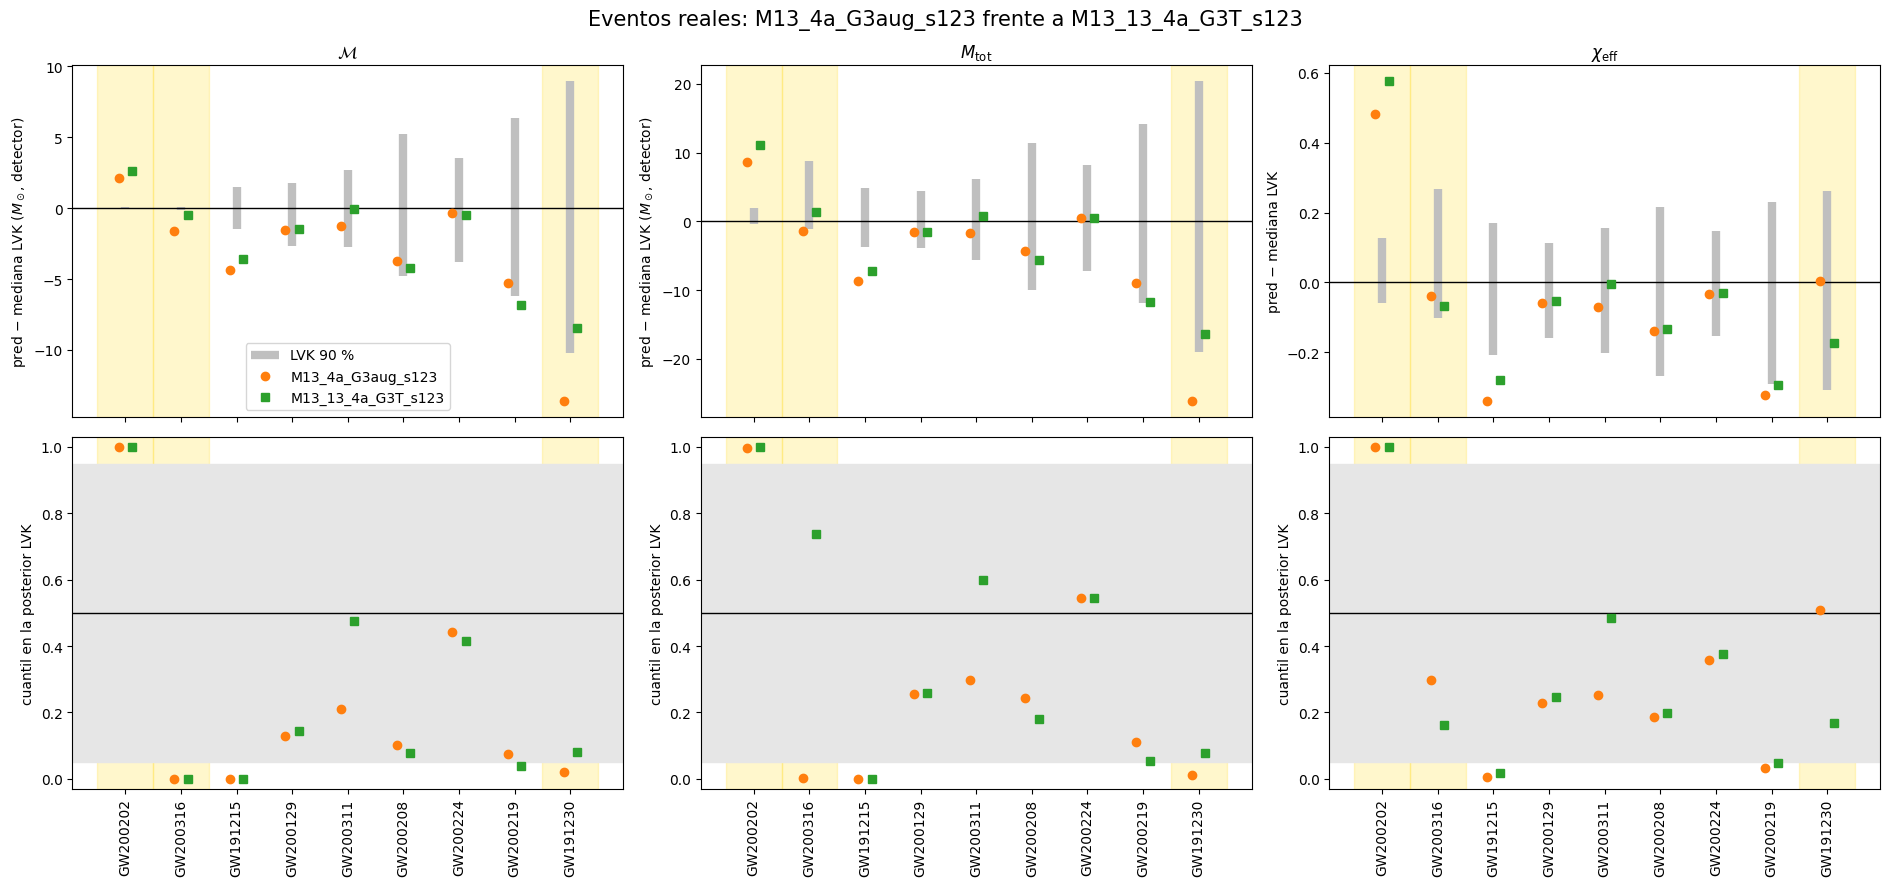

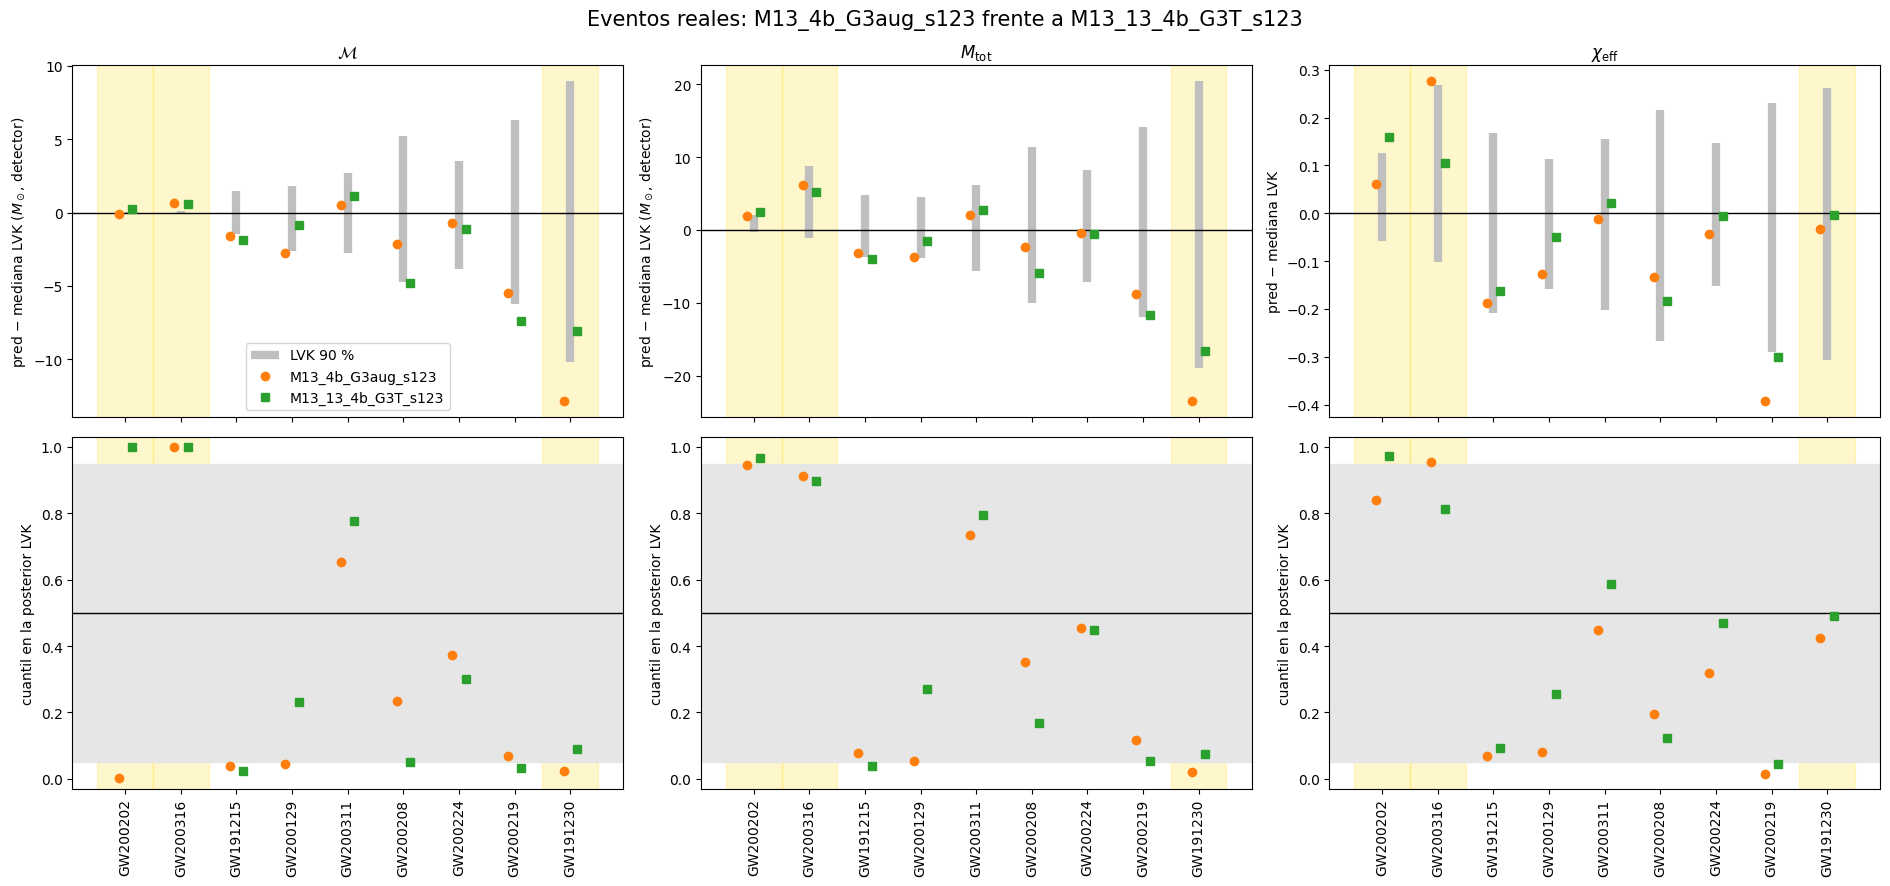

In [11]:
NICE_LABELS = {"chirp_mass": r"$\mathcal{M}$", "total_mass": r"$M_{\mathrm{tot}}$", "chi_eff": r"$\chi_\mathrm{eff}$"}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
figure_paths = []

def save_figure(fig, name):
    path = OUTPUT_DIR / f"M13_13_real_events_{RUN_STAMP}_{name}.png"
    with path.open("xb") as f:
        fig.savefig(f, format="png", dpi=150, bbox_inches="tight")
    figure_paths.append(str(path))

for (old, new), table in comparison_tables.items():
    fig, axes = plt.subplots(2, 3, figsize=(19, 9), sharex=True)
    fig.suptitle(f"Eventos reales: {old} frente a {new}", fontsize=15)
    for j, label in enumerate(LABELS):
        rows_ = table[table.label == label].reset_index(drop=True)
        x = np.arange(len(rows_))
        top, bottom = axes[0, j], axes[1, j]
        top.vlines(x, rows_.lvk_pe_lower90 - rows_.lvk_pe_median, rows_.lvk_pe_upper90 - rows_.lvk_pe_median,
                   color="0.75", linewidth=6, label="LVK 90 %")
        top.axhline(0, color="black", linewidth=1)
        bottom.axhspan(PE_Q[0], PE_Q[1], color="0.9")
        bottom.axhline(0.5, color="black", linewidth=1)
        for ax, column in ((top, "residual"), (bottom, "pred_quantile_in_lvk")):
            ax.plot(x - .12, rows_[f"{column}_old"], "o", color="C1", label=old)
            ax.plot(x + .12, rows_[f"{column}_new"], "s", color="C2", label=new)
            for i in x[rows_.highlight != ""]:
                ax.axvspan(i - .5, i + .5, color="gold", alpha=.2, zorder=0)
        unit = r" ($M_\odot$, detector)" if label != "chi_eff" else ""
        top.set(title=NICE_LABELS[label], ylabel="pred − mediana LVK" + unit)
        bottom.set(ylabel="cuantil en la posterior LVK", ylim=(-.03, 1.03))
        bottom.set_xticks(x)
        bottom.set_xticklabels([e.split("_")[0] for e in rows_.event], rotation=90)
    axes[0, 0].legend()
    fig.tight_layout()
    save_figure(fig, f"{old}_vs_{new}")
    plt.show()

## 12. Resumen JSON (modo `'x'`)

In [12]:
json_path = OUTPUT_DIR / f"M13_13_real_events_{RUN_STAMP}.json"
summary = dict(
    created_utc=datetime.now(timezone.utc).isoformat(), run_stamp=RUN_STAMP, descriptive=True,
    data_roles="real events: evaluation only; no model choice or fit; n = 9, no tests; no Mondrian",
    residual_definition="prediction - median of LVK posterior samples (detector frame)",
    gate=dict(model=GATE_TAG, tolerance=GATE_TOLERANCE, max_abs_delta=gate_max_abs_delta, passed=True,
              reference=str(M13_7_PREDICTIONS), rows=gate_table.to_dict("records")),
    provenance=dict(m13_7_run=M13_7_RUN, m13_7_notebook=str(M13_7_NOTEBOOK),
        m13_7_notebook_sha256=file_sha256(M13_7_NOTEBOOK), reused_m13_7_cells=reused_sources,
        cohort=str(EVENT_LIST_PATH), cohort_sha256=file_sha256(EVENT_LIST_PATH),
        g3_hdf5=str(G3_H5), generation_config=str(GEN_M13_PATH), train_config_contract=str(TRAIN_CFG_PATH),
        versions=dict(python=sys.version, numpy=np.__version__, torch=torch.__version__)),
    models=model_provenance, processing=processing_contract, events=EVENTS, processed=processed_provenance,
    lvk_posterior=dict(source="Zenodo 8177023 (GWTC-3 PE, v2)", variant=PE_VARIANT, group=PE_GROUP,
                       level=PE_LEVEL, files=pe_info),
    per_event=residuals.to_dict("records"), summary_by_model=summary_by_model.to_dict("records"),
    comparisons=[dict(old=old, new=new, rows=table.to_dict("records"))
                 for (old, new), table in comparison_tables.items()],
    highlighted_events=HIGHLIGHT, figures=figure_paths)
with json_path.open("x", encoding="utf-8") as f:
    # numpy scalars -> Python scalars; anything else as text.
    json.dump(summary, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Summary:", json_path)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M13_13/real_events/M13_13_real_events_20261110T130749Z.json


## 13. Conclusiones

Lectura (descriptiva, n = 9, una semilla, sin tests). El gate pasa: las 27 predicciones de 4b-G3 coinciden con M13.7 con una diferencia máxima de 1,4·10⁻¹⁴. Los cuatro modelos siguen por debajo de la mediana LVK en la chirp mass (de 6 a 8 de 9 eventos; mediana del residuo de −1,15 a −1,58), y G3T apenas mueve esa mediana. La mejora clara es GW191230, el evento de masa más alta. Con G3T, el residuo de 𝓜 pasa de −13,6 a −8,4 en 4a y de −12,9 a −8,1 en 4b, y el de M_tot de −26 a −16 y de −23,5 a −16,7. El cuantil en la posterior LVK pasa de unos 0,02 a unos 0,08–0,09. Esto es coherente con que el clic actuaba como “cronómetro” en las masas altas. GW200219 y GW200208 empeoran con las dos arquitecturas. En GW200202, 4a (con G3 y con G3T) sobreestima a la vez 𝓜, M_tot y χ_eff (χ_eff = 0,61 frente a 0,04), y 4b no lo hace. Son hipótesis, no resultados: el sesgo negativo que queda puede ser la regresión a la media del estimador o un desajuste entre simulación y datos reales distinto del clic (lo distingue el análisis del residuo esperado); lo de GW200202 sería la degeneración masa–χ_eff en 4a.